In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import time
import numpy as np
from scipy.linalg import expm
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
import pandas as pd
from utils.MyTools import MyTools

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'DejaVu Sans', 'Arial', 'Liberation Sans', 'Noto Sans CJK SC']
plt.rcParams['axes.unicode_minus'] = False

iris = load_iris()
data = iris.data
target = iris.target
arr3 = np.zeros((len(iris.target),3))
arr3[np.arange(len(iris.target)),iris.target] = 1

arr1 = np.random.choice(np.random.permutation(len(iris.data)),int(0.8*len(iris.data)),replace=False )
arr2 = np.setdiff1d(np.arange(len(iris.data)),arr1)
X = torch.tensor(iris.data,dtype=torch.float32)
y = torch.tensor(arr3,dtype=torch.float32)
X_train, X_test = X[arr1],X[arr2]
y_train, y_test = y[arr1],y[arr2]
y_train_ori,y_test_ori = iris.target[arr1],iris.target[arr2]
y_train_ori = torch.tensor(y_train_ori,dtype=torch.float32)
y_test_ori = torch.tensor(y_test_ori,dtype=torch.float32)

 1. 对比：手动 Adam vs PyTorch Adam 
[Epoch  0]  manual_loss=12.5000  torch_loss=12.5000
[Epoch 20]  manual_loss=2.7905  torch_loss=2.7905
[Epoch 40]  manual_loss=0.2116  torch_loss=0.2116
[Epoch 60]  manual_loss=0.0116  torch_loss=0.0116
[Epoch 80]  manual_loss=0.0039  torch_loss=0.0039
tensor([[-1.0214],
        [-0.9807]], requires_grad=True) tensor([[-1.0214],
        [-0.9807]], requires_grad=True)


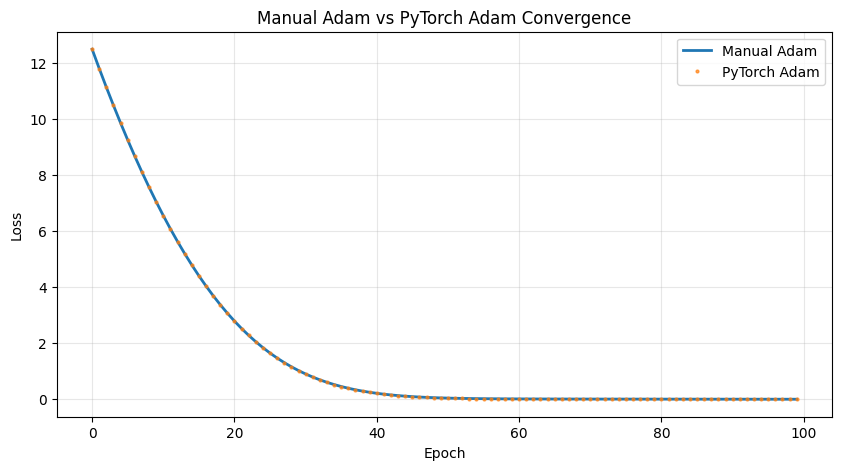


 2. 复杂函数优化：sin(x)+cos(y)+0.1xy 
[Complex Epoch   0] x=2.0100, y=1.0100, loss=1.6496
[Complex Epoch  40] x=2.4378, y=1.4173, loss=1.1604
[Complex Epoch  80] x=2.9250, y=1.8257, loss=0.5132
[Complex Epoch 120] x=3.4064, y=2.1831, loss=-0.0805
[Complex Epoch 160] x=3.8129, y=2.4430, loss=-0.4501
tensor([4.0986], requires_grad=True) tensor([2.5917], requires_grad=True)


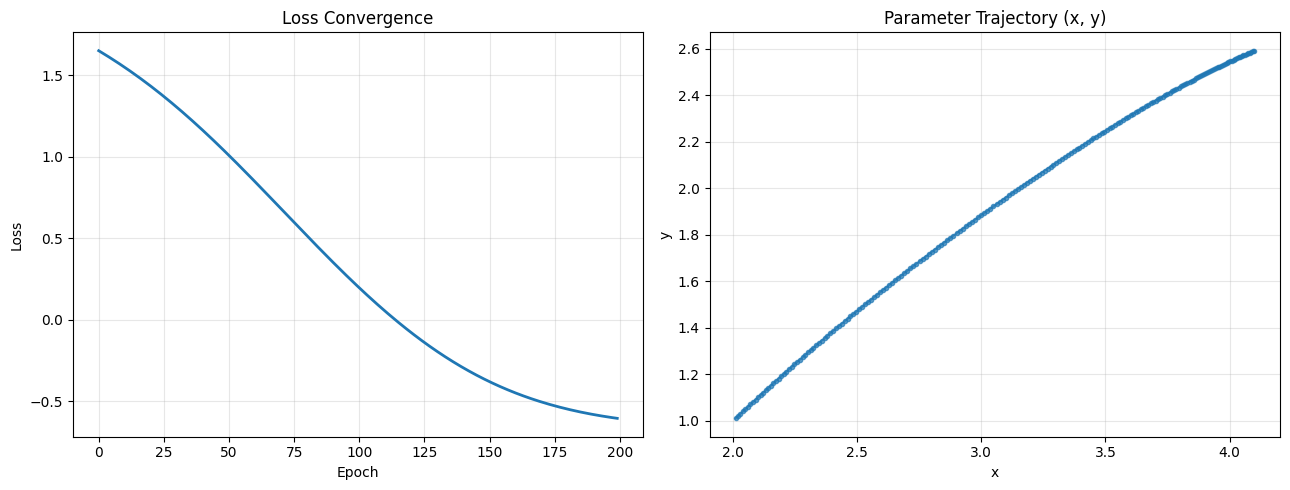

In [4]:
#自定义adam优化函数，和优化复杂函数
import torch
import matplotlib.pyplot as plt

# ====================== 手动实现 Adam（已修复：支持任意形状） ======================
class ManualAdam:
    def __init__(self, params, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.params = list(params)
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps

        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]
        self.t = 0

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

    def step(self):
        self.t += 1
        for i, p in enumerate(self.params):
            if p.grad is None:
                continue

            g = p.grad.data
            m = self.m[i]
            v = self.v[i]

            # 原位更新，和官方完全对齐
            m.mul_(self.beta1).add_(g, alpha=1 - self.beta1)
            v.mul_(self.beta2).addcmul_(g, g, value=1 - self.beta2)

            # 偏差校正
            m_hat = m / (1 - self.beta1 ** self.t)
            v_hat = v / (1 - self.beta2 ** self.t)

            # 参数更新
            p.data.addcdiv_(m_hat, torch.sqrt(v_hat) + self.eps, value=-self.lr)

# ====================== 测试1：手动 Adam vs 官方 Adam（2维参数 (2,1)） ======================
def test_adam_comparison(epochs=100, lr=0.1):
    # --- 手动 Adam ---
    x_manual = torch.tensor([[3.0], [2.0]], requires_grad=True)  #取两个点，看他们怎么接近最低值
    # x_manual = torch.tensor([4.0], requires_grad=True)
    opt_manual = ManualAdam([x_manual], lr=lr)
    losses_manual = []

    # --- 官方 Adam ---
    x_torch = torch.tensor([[3.0], [2.0]], requires_grad=True)
    # x_torch = torch.tensor([4.0], requires_grad=True)
    opt_torch = torch.optim.Adam([x_torch], lr=lr)
    losses_torch = []

    for epoch in range(epochs):
        # 手动更新
        loss_m = (x_manual**2 + 2*x_manual + 1).mean()
        opt_manual.zero_grad()
        loss_m.backward()
        opt_manual.step()
        losses_manual.append(loss_m.item())

        # 官方更新
        loss_t = (x_torch**2 + 2*x_torch + 1).mean()
        opt_torch.zero_grad()
        loss_t.backward()
        opt_torch.step()
        losses_torch.append(loss_t.item())

        # 每隔20轮输出一次
        if epoch % 20 == 0:
            print(f"[Epoch {epoch:2d}]  manual_loss={loss_m:.4f}  torch_loss={loss_t:.4f}")
    print(x_manual,x_torch)

    return losses_manual, losses_torch, x_manual, x_torch

# ====================== 测试2：复杂函数优化（sin(x)+cos(y)+0.1xy） ======================
def test_complex_optimization(epochs=200, lr=0.01):
    x = torch.tensor([2.0], requires_grad=True)
    y = torch.tensor([1.0], requires_grad=True)
    optimizer = torch.optim.Adam([x, y], lr=lr)

    x_hist, y_hist, loss_hist = [], [], []

    for epoch in range(epochs):
        loss = torch.sin(x) + torch.cos(y) + 0.1 * x * y

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        x_hist.append(x.item())
        y_hist.append(y.item())
        loss_hist.append(loss.item())

        if epoch % 40 == 0:
            print(f"[Complex Epoch {epoch:3d}] x={x.item():.4f}, y={y.item():.4f}, loss={loss.item():.4f}")
    print(x,y)

    return x_hist, y_hist, loss_hist

# ====================== 运行测试 & 绘图 ======================
if __name__ == "__main__":
    print("=" * 50)
    print(" 1. 对比：手动 Adam vs PyTorch Adam ")
    print("=" * 50)
    manual_losses, torch_losses, x_manual, x_torch = test_adam_comparison(epochs=100, lr=0.1)

    # 对比图
    plt.figure(figsize=(10, 5))
    plt.plot(manual_losses, label="Manual Adam", linewidth=2)
    plt.plot(torch_losses, 'o', markersize=2, label="PyTorch Adam", alpha=0.7)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Manual Adam vs PyTorch Adam Convergence")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    print("\n" + "=" * 50)
    print(" 2. 复杂函数优化：sin(x)+cos(y)+0.1xy ")
    print("=" * 50)
    x_hist, y_hist, loss_hist = test_complex_optimization(epochs=200, lr=0.01)

    # 复杂优化可视化
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    ax1.plot(loss_hist, linewidth=2)
    ax1.set_title("Loss Convergence")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.grid(True, alpha=0.3)

    ax2.plot(x_hist, y_hist, 'o-', markersize=3, alpha=0.7)
    ax2.set_title("Parameter Trajectory (x, y)")
    ax2.set_xlabel("x")
    ax2.set_ylabel("y")
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
#deepseek的优化函数：
import torch
import math

class DeepSeekAdamW(torch.optim.Optimizer):
    """
    对齐 DeepSeek V2/V3 开源 fused_adam + DeepSeekOptimizer
    核心：AdamW + β₂=0.95 + 分组 decay + 分层 lr + 梯度裁剪
    """
    def __init__(self, params, lr=2.2e-4, betas=(0.9, 0.95),
                 eps=1e-8, weight_decay=0.1, clip_norm=1.0,
                 llrd_ratio=0.9):
        defaults = dict(lr=lr, betas=betas, eps=eps,
                        weight_decay=weight_decay, clip_norm=clip_norm,
                        llrd_ratio=llrd_ratio)
        super().__init__(params, defaults)

    def __setstate__(self, state):
        super().__setstate__(state)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group['lr']
            beta1, beta2 = group['betas']
            eps = group['eps']
            weight_decay = group['weight_decay']
            clip_norm = group['clip_norm']

            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad
                if grad.is_sparse:
                    raise RuntimeError('DeepSeekAdamW 不支持稀疏梯度')

                # ---------------------- 1. 按层梯度裁剪 ----------------------
                torch.nn.utils.clip_grad_norm_(p, clip_norm)

                # ---------------------- 2. 初始化状态 ----------------------
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)

                exp_avg, exp_avg_sq = state['exp_avg'], state['exp_avg_sq']
                state['step'] += 1

                # ---------------------- 3. 一阶、二阶矩更新 ----------------------
                exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)
                exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                # ---------------------- 4. 偏差校正 ----------------------
                bias_correction1 = 1 - beta1 ** state['step']
                bias_correction2 = 1 - beta2 ** state['step']
                denom = (exp_avg_sq.sqrt() / math.sqrt(bias_correction2)).add_(eps)

                # ---------------------- 5. 解耦权重衰减（AdamW 核心） ----------------------
                p.data.mul_(1 - lr * weight_decay)

                # ---------------------- 6. 参数更新 ----------------------
                step_size = lr / bias_correction1
                p.data.addcdiv_(exp_avg, denom, value=-step_size)
        return loss

def get_deepseek_optimizer(model, base_lr=2.2e-4, weight_decay=0.1, llrd_ratio=0.9):
    """
    构造 DeepSeek 风格分组优化器：
    - bias / RMSNorm.weight 不做 weight decay
    - 分层学习率（底层 lr 小，顶层 lr 大）
    """
    no_decay = ["bias", "RMSNorm.weight", "LayerNorm.weight"]
    optimizer_grouped_parameters = []

    # 分层学习率
    layers = model.layers if hasattr(model, 'layers') else model.encoder.layer
    n_layers = len(layers)

    for i, layer in enumerate(layers):
        # 越深的层，lr 越大
        layer_lr = base_lr * (llrd_ratio ** (n_layers - i - 1))
        # 区分 decay / no decay
        params_decay = [p for n, p in layer.named_parameters() if not any(nd in n for nd in no_decay)]
        params_no_decay = [p for n, p in layer.named_parameters() if any(nd in n for nd in no_decay)]

        optimizer_grouped_parameters.append({
            "params": params_decay,
            "weight_decay": weight_decay,
            "lr": layer_lr
        })
        optimizer_grouped_parameters.append({
            "params": params_no_decay,
            "weight_decay": 0.0,
            "lr": layer_lr
        })

    # 输出头单独设置
    head_params = [p for n, p in model.named_parameters() if "lm_head" in n]
    optimizer_grouped_parameters.append({
        "params": head_params,
        "weight_decay": weight_decay,
        "lr": base_lr
    })

    return DeepSeekAdamW(optimizer_grouped_parameters, lr=base_lr)







In [ ]:
#比较几种优化器
import torch
import math
import matplotlib.pyplot as plt

# ===================== 1. 各类优化器实现 =====================
# 1. 带动量 SGD
class MomentumSGD:
    def __init__(self, params, lr=0.01, momentum=0.9):
        self.params = list(params)
        self.lr = lr
        self.momentum = momentum
        self.velocities = [torch.zeros_like(p) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

    def step(self):
        for idx, p in enumerate(self.params):
            if p.grad is None:
                continue
            grad = p.grad.data
            self.velocities[idx].mul_(self.momentum).add_(grad)
            p.data.add_(self.velocities[idx], alpha=-self.lr)

# 2. 标准 Adam
class Adam:
    def __init__(self, params, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.params = list(params)
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0
        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

    def step(self):
        self.t += 1
        beta1_t = self.beta1 ** self.t
        beta2_t = self.beta2 ** self.t
        for idx, p in enumerate(self.params):
            if p.grad is None:
                continue
            grad = p.grad.data
            self.m[idx].mul_(self.beta1).add_(grad, alpha=1 - self.beta1)
            self.v[idx].mul_(self.beta2).addcmul_(grad, grad, value=1 - self.beta2)
            m_hat = self.m[idx] / (1 - beta1_t)
            v_hat = self.v[idx] / (1 - beta2_t)
            denom = torch.sqrt(v_hat) + self.eps
            p.data.addcdiv_(m_hat, denom, value=-self.lr)

# 3. 标准 AdamW
class AdamW:
    def __init__(self, params, lr=0.001, beta1=0.9, beta2=0.999, 
                 eps=1e-8, weight_decay=1e-2):
        self.params = list(params)
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.weight_decay = weight_decay
        self.t = 0
        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

    def step(self):
        self.t += 1
        beta1_t = self.beta1 ** self.t
        beta2_t = self.beta2 ** self.t
        for idx, p in enumerate(self.params):
            if p.grad is None:
                continue
            grad = p.grad.data
            self.m[idx].mul_(self.beta1).add_(grad, alpha=1 - self.beta1)
            self.v[idx].mul_(self.beta2).addcmul_(grad, grad, value=1 - self.beta2)
            m_hat = self.m[idx] / (1 - beta1_t)
            v_hat = self.v[idx] / (1 - beta2_t)
            denom = torch.sqrt(v_hat) + self.eps
            update = m_hat / denom
            update += self.weight_decay * p.data
            p.data.add_(update, alpha=-self.lr)

# 4. DeepSeek 定制 AdamW
class DeepSeekAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=2.2e-4, betas=(0.9, 0.95),
                 eps=1e-8, weight_decay=0.1, clip_norm=1.0,
                 llrd_ratio=0.9):
        defaults = dict(lr=lr, betas=betas, eps=eps,
                        weight_decay=weight_decay, clip_norm=clip_norm,
                        llrd_ratio=llrd_ratio)
        super().__init__(params, defaults)

    def __setstate__(self, state):
        super().__setstate__(state)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group['lr']
            beta1, beta2 = group['betas']
            eps = group['eps']
            weight_decay = group['weight_decay']
            clip_norm = group['clip_norm']

            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad
                if grad.is_sparse:
                    raise RuntimeError('DeepSeekAdamW 不支持稀疏梯度')

                torch.nn.utils.clip_grad_norm_(p, clip_norm)
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)

                exp_avg, exp_avg_sq = state['exp_avg'], state['exp_avg_sq']
                state['step'] += 1

                exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)
                exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                bias_correction1 = 1 - beta1 ** state['step']
                bias_correction2 = 1 - beta2 ** state['step']
                denom = (exp_avg_sq.sqrt() / math.sqrt(bias_correction2)).add_(eps)

                p.data.mul_(1 - lr * weight_decay)
                step_size = lr / bias_correction1
                p.data.addcdiv_(exp_avg, denom, value=-step_size)
        return loss

# ===================== 2. 统一对比实验 =====================
def run_comparison(lr=0.01, epochs=400):
    optim_configs = {
        "MomentumSGD": {"opt_cls": MomentumSGD, "kwargs": {"lr": lr, "momentum": 0.9}},
        "Adam": {"opt_cls": Adam, "kwargs": {"lr": lr}},
        "AdamW": {"opt_cls": AdamW, "kwargs": {"lr": lr, "weight_decay": 0.01}},
        "DeepSeekAdamW": {"opt_cls": DeepSeekAdamW, "kwargs": {"lr": lr, "weight_decay": 0.1}}
    }

    results = {}
    final_info = {}

    for name, cfg in optim_configs.items():
        # 重置参数，保证初始条件完全一致
        x = torch.tensor([-1.0], requires_grad=True)
        opt = cfg["opt_cls"]([x], **cfg["kwargs"])
        loss_hist = []

        for _ in range(epochs):
            loss = x**4 - 3 * x**3 + 2
            opt.zero_grad()
            loss.backward()
            opt.step()
            loss_hist.append(loss.item())

        results[name] = loss_hist
        final_info[name] = (x.item(), loss_hist[-1])
        print(f"{name:15s} | final_x = {x.item():.4f} | final_loss = {loss_hist[-1]:.4f}")

    return results, final_info

# 执行实验
if __name__ == "__main__":
    loss_records, final_data = run_comparison(lr=0.01, epochs=400)

    # ===================== 3. 绘图 =====================
    plt.figure(figsize=(12, 6))
    for opt_name, losses in loss_records.items():
        plt.plot(losses, label=opt_name, linewidth=2)

    plt.xlabel("Epoch")
    plt.ylabel("Loss (log scale)")
    plt.title("Optimizer Comparison: SGD / Adam / AdamW / DeepSeekAdamW")
    plt.legend()
    plt.yscale("log")
    plt.grid(alpha=0.3)
    plt.show()

In [ ]:
class TransformerAnalyzer:
    """Transformer 分析工具类"""
    
    def __init__(self, model):
        self.model = model
        self.analysis_results = {}
    
    def analyze_layers(self):
        """分析所有层"""
        results = {}
        
        # 编码器
        results['encoder'] = self._analyze_module(
            self.model.encoder, 
            "Encoder", 
            depth=0
        )
        
        # 解码器
        results['decoder'] = self._analyze_module(
            self.model.decoder, 
            "Decoder", 
            depth=0
        )
        
        self.analysis_results = results
        return results
    
    def _analyze_module(self, module, name, depth):
        """递归分析模块"""
        analysis = {
            'name': name,
            'type': module.__class__.__name__,
            'depth': depth,
            'parameters': {},
            'children': [],
            'total_params': 0
        }
        
        # 统计参数
        for param_name, param in module.named_parameters():
            if param_name.startswith('weight') or param_name.startswith('bias'):
                param_count = param.numel()
                analysis['parameters'][param_name] = {
                    'shape': tuple(param.shape),
                    'count': param_count,
                    'trainable': param.requires_grad
                }
                analysis['total_params'] += param_count
        
        # 递归分析子模块
        for child_name, child in module.named_children():
            child_analysis = self._analyze_module(
                child, 
                f"{name}.{child_name}", 
                depth + 1
            )
            analysis['children'].append(child_analysis)
            analysis['total_params'] += child_analysis['total_params']
        
        return analysis
    
    def print_summary(self):
        """打印汇总信息"""
        if not self.analysis_results:
            self.analyze_layers()
        
        print("\n" + "="*60)
        print("TRANSFORMER 结构分析报告")
        print("="*60)
        
        self._print_module_summary(self.analysis_results['encoder'], 0)
        self._print_module_summary(self.analysis_results['decoder'], 0)
        
        total_params = (
            self.analysis_results['encoder']['total_params'] + 
            self.analysis_results['decoder']['total_params']
        )
        print(f"\n总参数数量: {total_params:,}")
    
    def _print_module_summary(self, module_info, indent):
        """打印模块信息"""
        indent_str = "  " * indent
        print(f"\n{indent_str}{module_info['name']} ({module_info['type']})")
        print(f"{indent_str}  总参数: {module_info['total_params']:,}")
        
        # 打印主要参数
        if module_info['parameters']:
            for param_name, param_info in module_info['parameters'].items():
                print(f"{indent_str}  {param_name}: {param_info['shape']} "
                      f"({param_info['count']:,} params)")
        
        # 递归打印子模块
        for child in module_info['children']:
            self._print_module_summary(child, indent + 2)

if __name__ == "__main__":
    # 使用分析工具
    analyzer = TransformerAnalyzer(transformer)
    analyzer.print_summary()

In [ ]:
transformer

In [2]:
#怎么识别无效神经元。实现这一目标，主要可以分为三步走：识别 -> 移除 -> 微调。

import torch
import torch.nn as nn
import torch.nn.utils.prune as prune
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 加载 Iris 数据集
iris = load_iris()
X = iris.data          # shape: (150, 4)
y = iris.target        # shape: (150,)

# 转换为 PyTorch 张量
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)  # 分类标签用 long 类型

# 划分训练/测试集 (80% 训练, 20% 测试)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 标准化（对输入特征）
scaler = StandardScaler()
X_train = torch.tensor(scaler.fit_transform(X_train), dtype=torch.float32)
X_test = torch.tensor(scaler.transform(X_test), dtype=torch.float32)

print(f"训练集大小: {X_train.shape[0]}, 测试集大小: {X_test.shape[0]}")
print(f"输入特征维度: {X_train.shape[1]}, 类别数: {len(torch.unique(y))}")




训练集大小: 120, 测试集大小: 30
输入特征维度: 4, 类别数: 3


In [29]:
#构建神经网络：
class MyNN(nn.Module):
    def __init__(self, input_size=4, hidden_size=50, output_size=3):
        super(MyNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)
        # 注意：不需要手动置零初始化
    
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x
#训练神经网络
def train_neural_network(X_train, X_test, y_train, y_test, epochs=500, lr=0.001):
    input_size = X_train.shape[1]
    y_train_ori = torch.argmax(y_train,axis=1)
    y_test_ori = torch.argmax(y_test,axis=1)
    output_size = len(torch.unique(y_train_ori))
    # print(y_train.shape,output_size)
    model = MyNN(input_size=input_size, hidden_size=50, output_size=output_size) #模型
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)   #优化器
    criterion = nn.CrossEntropyLoss()  # 分类损失
    
    train_losses, test_losses = [], []
    train_accs, test_accs = [], []
    
    for epoch in range(epochs):
        # 训练
        model.train()          #模型置于训练状态
        optimizer.zero_grad()  #清除梯度
        outputs = model(X_train) #正向传播
        # print(outputs.shape,y_train.shape)
        loss = criterion(outputs, y_train)  #记录损失数据
        loss.backward() #反向传播
        optimizer.step() # 更新参数
        
        # 评估
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = criterion(test_outputs, y_test)
            
            # 计算准确率
            _, pred_train = torch.max(outputs, 1)
            _, pred_test = torch.max(test_outputs, 1)
            train_acc = (pred_train == y_train_ori).float().mean()
            test_acc = (pred_test == y_test_ori).float().mean()
        
        train_losses.append(loss.item())
        test_losses.append(test_loss.item())
        train_accs.append(train_acc.item())
        test_accs.append(test_acc.item())
        
        if epoch % 100 == 0:
            print(f'Epoch {epoch:3d}: Train Loss = {loss.item():.4f}, Test Loss = {test_loss.item():.4f}, '
                  f'Train Acc = {train_acc.item():.2%}, Test Acc = {test_acc.item():.2%}')
    
    return model, train_losses, test_losses, train_accs, test_accs

#执行训练 
print("=== 训练原始模型 (Iris 分类) ===")
model_original, train_loss, test_loss, train_acc, test_acc = train_neural_network(
    X_train, X_test, y_train, y_test, epochs=500
)
print(f"原始模型参数数量: {sum(p.numel() for p in model_original.parameters())}")
print(f"最终测试准确率: {test_acc[-1]:.2%}")

#可视化训练曲线
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_loss, label='Train Loss')
plt.plot(test_loss, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('训练损失')

plt.subplot(1, 2, 2)
plt.plot(train_acc, label='Train Acc')
plt.plot(test_acc, label='Test Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('训练准确率')
plt.show()



In [35]:
import torch
import torch.nn as nn
import torch.nn.utils.prune as prune
#非结构化剪枝：
def apply_unstructured_pruning(model, amount=0.5):
    prune.l1_unstructured(model.fc1, name='weight', amount=amount)
    prune.l1_unstructured(model.fc2, name='weight', amount=amount)
    return model

def check_sparsity(model):
    total = 0
    zero = 0
    for name, param in model.named_parameters():
        if 'weight' in name:
            total += param.numel()
            zero += (param == 0).sum().item()
    return zero / total

# 复制原始模型
import copy
model_unstructured = copy.deepcopy(model_original)
apply_unstructured_pruning(model_unstructured, amount=0.5)
print(f"非结构化剪枝后稀疏度: {check_sparsity(model_unstructured):.2%}")

# 微调剪枝后的模型（使用分类损失）
def fine_tune_classification(model, X_train, y_train, X_test, y_test, epochs=100, lr=0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test)
        test_loss = criterion(test_outputs, y_test)
        _, pred_test = torch.max(test_outputs, 1)
        test_acc = (pred_test == y_test).float().mean()
    return test_loss.item(), test_acc.item()

test_loss_unstruct, test_acc_unstruct = fine_tune_classification(
    model_unstructured, X_train, y_train, X_test, y_test, epochs=100
)
print(f"方案一（非结构化剪枝）微调后测试损失: {test_loss_unstruct:.4f}, 准确率: {test_acc_unstruct:.2%}")

非结构化剪枝后稀疏度: 0.00%
方案一（非结构化剪枝）微调后测试损失: 0.0509, 准确率: 100.00%


In [36]:
#结构化剪枝：
def structured_prune(model, keep_ratio=0.5):
    weight1 = model.fc1.weight.data
    importance = torch.norm(weight1, dim=1)
    hidden = weight1.size(0)
    k = max(1, int(hidden * keep_ratio))
    _, indices = torch.topk(importance, k)
    indices = indices.sort()[0]
    
    input_size = model.fc1.in_features
    output_size = model.fc2.out_features
    new_model = MyNN(input_size=input_size, hidden_size=k, output_size=output_size)
    
    new_model.fc1.weight.data = weight1[indices, :]
    new_model.fc1.bias.data = model.fc1.bias.data[indices]
    new_model.fc2.weight.data = model.fc2.weight.data[:, indices]
    new_model.fc2.bias.data = model.fc2.bias.data
    return new_model

model_structured = structured_prune(model_original, keep_ratio=0.5)
print(f"结构化剪枝后模型参数数量: {sum(p.numel() for p in model_structured.parameters())}")

# 微调
test_loss_struct, test_acc_struct = fine_tune_classification(
    model_structured, X_train, y_train, X_test, y_test, epochs=100
)
print(f"方案二（结构化剪枝）微调后测试损失: {test_loss_struct:.4f}, 准确率: {test_acc_struct:.2%}")

结构化剪枝后模型参数数量: 203
方案二（结构化剪枝）微调后测试损失: 0.0737, 准确率: 100.00%


In [ ]:
#使用torch 和 adam优化写神经网络预测鸢尾花分类
param1 = []
param2 = []
class MyNN(nn.Module):
    def __init__(self, input_size=3, hidden_size=50, output_size=3):
        super(MyNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc1.weight.data.zero_()
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)
        self.fc2.weight.data.zero_()
    
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

def train_neural_network(X_train,X_test,y_train,y_test):
    # 生成模拟数据
    # torch.manual_seed(42)
    # n_samples = 1000
    # input_size = 10

    input_size= X_train.shape[1]
    
    # 真实函数: y = sum(x^2) + noise
    # X = torch.randn(n_samples, input_size)
    # y = torch.sum(X**2, dim=1, keepdim=True) + 0.1 * torch.randn(n_samples, 1)

    # 划分训练测试集
    # train_size = int(0.8 * n_samples)
    # X_train, X_test = X[:train_size], X[train_size:]
    # y_train, y_test = y[:train_size], y[train_size:]


    
    # 创建模型和优化器
    model = MyNN(input_size=input_size)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
    criterion = nn.MSELoss()
    
    train_losses, test_losses = [], []
    
    for epoch in range(500):
        model.train()
        # 训练步骤
        optimizer.zero_grad()
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        loss.backward()
        # param.append(model.fc1.weight.grad.clone())  #保存反向传播后的梯度（step 之前）
        optimizer.step()
        # param1.append(model.fc1.weight.detach().clone())  #保存更新后的权重（step 之后） linear.weight.data.clone()
        
        # 评估步骤，这里使用的测试机评估的
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = criterion(test_outputs, y_test)
        
        train_losses.append(loss.item())
        test_losses.append(test_loss.item())
        
        if epoch % 100 == 0:
            print(f'Epoch {epoch}: Train Loss = {loss.item():.4f}, Test Loss = {test_loss.item():.4f}')
    
    return train_losses, test_losses,model





print("\n=== 神经网络训练 ===")
train_loss, test_loss,mdl = train_neural_network(X_train[:,1:],X_test[:,1:],y_train,y_test)

# 绘制训练曲线
plt.figure(figsize=(10, 6))
plt.plot(train_loss, label='Training Loss')
plt.plot(test_loss, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Neural Network Training with Adam')
plt.legend()
plt.yscale('log')  # 使用对数坐标更好地观察收敛
plt.grid(True)
plt.show()

In [ ]:
#当前cell + 下一个cell。查看预测错误数据的位置，绘制对应点的坐标
from utils.MyTools import MyTools
data = torch.tensor(iris.data,dtype=torch.float32)
target = torch.tensor(iris.target,dtype=torch.float32)
y_hat = mdl(data[:,1:])
y_hat = torch.argmax(y_hat,axis=1)

mask = (y_hat != target)
y_hat[mask] = 3
S,sigma,Vt = np.linalg.svd(iris.data[:,1:])

In [ ]:
%matplotlib widget
from IPython.display import clear_output

fig,ax = MyTools.myPlot3dPoints(data,y_hat,show=False)
clear_output(wait=True)
# fig,ax = MyTools.myPlot3dPoints(param1[199])
fig,ax = MyTools.myPlotV(Vt.T,fig=fig,ax=ax,c=['r','g','b'])
clear_output(wait=True) #清除静态图形
# plt.show()

In [ ]:
# 查看模型的准确率：
irisdata = torch.tensor(iris.data[:,1:],dtype=torch.float32)
target = torch.tensor(iris.target,dtype=torch.float32)
y_hat = torch.argmax(mdl(irisdata),axis=1)

torch.where(target - y_hat !=0)

In [ ]:
#使用多个高斯分布对概率进行拆解
from utils.MyTools import MyTools
t = MyTools.myCumCnt(iris.data,calCol=2,typecol=iris.target,cumflag='y')

In [ ]:
# 更换为Vt 作为神经元 对N*2矩阵，等效还原到2*2的矩阵中
from utils.MyTools import MyTools
data = iris.data
t = data[:,2:4]
t2 = t.T@t
MyTools.myVectorAngle(t),MyTools.myVectorAngle(t2)
MyTools.myVectorArea(t),MyTools.myVectorArea(t2)
np.linalg.norm(t,axis=0),np.linalg.norm(t2,axis=0)
S,sigma,Vt = np.linalg.svd(t)
SS,ssigma,VVt = np.linalg.svd(t2)
#构造二维 中等效于data[:,2:4] 的两个向量
t = np.zeros((len(S),len(sigma)))
t[range(len(sigma)),range(len(sigma))] = sigma
newarr = SS@np.diag(sigma)@Vt

In [ ]:
#比较原矩阵data[:,2:4] 和新构造的 2维矩阵是否相同。包含矩阵包含向量的模长 ，角度，面积
np.linalg.norm(newarr,axis=0),np.linalg.norm(data[:,2:4],axis=0)
MyTools.myVectorAngle(newarr),MyTools.myVectorAngle(data[:,2:4])
MyTools.myVectorArea(newarr),MyTools.myVectorArea(data[:,2:4])

In [ ]:
#把SVD分解的Vt 作为神经元，来计算，然后调整
S,sigma,Vt = np.linalg.svd(iris.data[iris.target==0])
S,sigma,t = np.linalg.svd(iris.data[iris.target==1])
Vt = np.vstack((Vt,t))
S,sigma,t = np.linalg.svd(iris.data[iris.target==2])
Vt = np.vstack((Vt,t))

In [ ]:
Vt.T

In [ ]:
# 这个问题搞不定。继续修正：其实nt 应该不是真实的t，因为任何一个和t的模长和夹角一样，就对应这个t
# 这些在不同位置的t，它们的指向其实并不一样。怎么真实还原这些指向呢？ 
angle=10*np.pi/180
rv = np.array([[np.cos(angle),-np.sin(angle)],[np.sin(angle),np.cos(angle)]])
rv@nt

t1 = MyTools.myVrotaion(t[:,0],vrect,theta=10*np.pi/180)
t2 = MyTools.myVrotaion(t[:,1],vrect,theta=10*np.pi/180)
i1,i2,i=np.linalg.svd(np.column_stack((t1,t2)))

In [ ]:
nt

In [ ]:
i = np.column_stack((nt22[:,0]*10,nt22[:,1]*0.1))
MyTools.myVectorAngle(i),MyTools.myVectorAngle(i.T@i)

In [ ]:
i = np.sqrt(i)
nt33 = UU@np.diag(i)@Vt
MyTools.myVectorAngle(nt33)

In [ ]:
i = np.sqrt(i)
nt99 = UU@np.diag(i)@Vt
MyTools.myVectorAngle(nt99)

In [ ]:
B = np.array([[0.8,-0.01],[0,8.0]])
i = B
MyTools.myVectorAngle(i),MyTools.myVectorAngle(i[:,0],np.array([1,0])),MyTools.myVectorAngle(i[:,1],np.array([1,0]))


In [ ]:
i = i.T@i

In [ ]:
MyTools.myVectorAngle(i),MyTools.myVectorAngle(i[:,0],np.array([1,0])),MyTools.myVectorAngle(i[:,1],np.array([1,0]))

In [ ]:
i

In [ ]:
UU@np.diag(sigma)@Vt,MyTools.myVectorAngle(UU@np.diag(sigma*10)@Vt)

In [ ]:
#不断的执行t.T@t 最后的结果偏向于哪个向量
i2 = []
for j in np.linspace(1,8,20):
    # i = np.power(sigma,j)
    i = sigma*j
    t_2 = UU@np.diag(i)@Vt
    i2.append(MyTools.myVectorAngle(t_2))
    print(MyTools.myVectorAngle(t_2))


In [ ]:
plt.plot(range(len(i2)),i2)

In [ ]:
#taylor_approximation
import numpy as np
def taylor_approximation(x, y=None, degree=5):
    """
    通过多项式拟合数据点，生成可调用的近似函数（视为泰勒级数近似）。
    参数
    ----------
    x : array_like
        如果 y 为 None，则 x 视为 y 值，x 坐标默认为 0,1,2,...
        如果 y 不为 None，则 x 为 x 坐标，y 为 y 坐标。
    y : array_like, 可选
        y 值。
    degree : int, 默认 5
        多项式阶数（即泰勒级数的项数为 degree+1）。

    返回
    -------
    function
        接受 x 值（标量或数组），返回近似值。
    """
    if y is None:
        # 仅传入一个数组，假设它表示 y，x 默认索引
        y = np.asarray(x)
        x = np.arange(len(y))
    else:
        x = np.asarray(x)
        y = np.asarray(y)
    # 使用 polyfit 拟合多项式
    coeffs = np.polyfit(x, y, deg=degree)   # 系数从高次到低次
    # 转换为从常数项开始的泰勒形式（低次到高次）
    coeffs_taylor = coeffs[::-1]  # 现在 coeffs_taylor[0] 是常数项

    def approx_func(x_eval):
        # 使用 Horner 法计算多项式值
        x_eval = np.asarray(x_eval)
        result = np.zeros_like(x_eval, dtype=float)
        for c in coeffs_taylor[::-1]:
            result = result * x_eval + c
        return result

    return approx_func,coeffs_taylor

In [ ]:
#拉普拉斯拟合
import numpy as np
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error

def laplace_fit(t, y, max_terms=3, include_constant=False):
    """
    自动拟合衰减信号为指数和模型，返回拉普拉斯变换表达式。

    参数
    ----------
    t : array_like, 1D
        时间点（可为非等间隔）
    y : array_like, 1D
        信号值
    max_terms : int, 默认 3
        最大指数项数（1, 2, 3）
    include_constant : bool, 默认 False
        是否允许模型包含常数项（用于信号不归零的情况）

    返回
    -------
    dict
        {
            'model_name': str,
            'params': dict,          # 参数名 -> 值
            'formula': str,          # 拉普拉斯变换表达式
            'aic': float,
            'rmse': float,
            'y_fitted': ndarray,     # 拟合值
            'model_function': callable  # 可调用模型函数
        }
    """
    t = np.asarray(t, dtype=float)
    y = np.asarray(y, dtype=float)
    if t.ndim != 1 or y.ndim != 1 or len(t) != len(y):
        raise ValueError("t 和 y 必须为一维且长度相同")

    # ----- 定义模型函数（返回可调用对象）-----
    def make_model(n_terms, const=False):
        """生成带有 n_terms 个指数项（以及可选的常数项）的模型函数"""
        def model_func(t, *params):
            # params: A1, λ1, A2, λ2, ..., [C]
            m = n_terms
            result = np.zeros_like(t, dtype=float)
            for i in range(m):
                A = params[2*i]
                lam = params[2*i + 1]
                result += A * np.exp(-lam * t)
            if const:
                result += params[-1]  # 常数项
            return result
        return model_func

    # ----- 定义不同模型及其初始猜测、参数边界 -----
    models = []
    for n in range(1, max_terms+1):
        # 不包含常数项
        p0 = []
        bounds = ([], [])
        for i in range(n):
            # 初始猜测: 幅度从数据首尾差值估计，衰减系数从时间尺度估计
            A_guess = (y[0] - y[-1]) / n * 0.8 if n == 1 else (y[0] - y[-1]) / n
            lam_guess = 1.0 / (t[-1] - t[0]) * (0.5 + i*0.5)  # 给不同项不同特征频率
            p0.extend([A_guess, lam_guess])
            bounds[0].extend([-np.inf, 1e-6])   # 幅度无界，衰减系数>0
            bounds[1].extend([np.inf, np.inf])
        if include_constant:
            p0.append(y[-1])  # 常数项初始为尾部均值
            bounds[0].append(-np.inf)
            bounds[1].append(np.inf)
        models.append({
            'n_terms': n,
            'const': include_constant,
            'func': make_model(n, include_constant),
            'p0': p0,
            'bounds': bounds
        })

    # ----- 拟合所有候选模型，计算 AIC -----
    best_model = None
    best_aic = np.inf
    best_result = None

    for model_info in models:
        try:
            popt, pcov = curve_fit(model_info['func'], t, y,
                                   p0=model_info['p0'],
                                   bounds=model_info['bounds'],
                                   maxfev=10000)
            y_fit = model_info['func'](t, *popt)
            rmse = np.sqrt(mean_squared_error(y, y_fit))
            n_params = len(popt)
            n_data = len(y)
            aic = n_data * np.log(rmse**2) + 2 * n_params   # 简化 AIC
            # 构造参数字典
            param_names = []
            param_vals = {}
            for i in range(model_info['n_terms']):
                A = popt[2*i]
                lam = popt[2*i+1]
                param_vals[f'A{i+1}'] = A
                param_vals[f'λ{i+1}'] = lam
                param_names.extend([f'A{i+1}', f'λ{i+1}'])
            if model_info['const']:
                param_vals['C'] = popt[-1]
                param_names.append('C')
            # 更新最佳模型
            if aic < best_aic:
                best_aic = aic
                best_model = {
                    'n_terms': model_info['n_terms'],
                    'const': model_info['const'],
                    'params': param_vals,
                    'param_names': param_names,
                    'popt': popt,
                    'func': model_info['func'],
                    'rmse': rmse,
                    'aic': aic,
                    'y_fit': y_fit
                }
        except Exception as e:
            # 拟合失败则跳过
            continue

    if best_model is None:
        raise RuntimeError("所有模型拟合失败，请检查数据或放宽参数边界")

    # ----- 构造输出信息 -----
    n = best_model['n_terms']
    const = best_model['const']
    params = best_model['params']

    # 构造模型名称
    name_parts = [f"{n}指数" if n>1 else "单指数"]
    if const:
        name_parts.append("+ 常数项")
    model_name = "".join(name_parts)

    # 构造拉普拉斯变换公式字符串
    terms = []
    for i in range(1, n+1):
        A = params[f'A{i}']
        lam = params[f'λ{i}']
        # 格式化数字
        A_str = f"{A:.4g}"
        lam_str = f"{lam:.4g}"
        sign = "+" if A >= 0 else "-"
        abs_A = abs(A)
        if i == 1:
            terms.append(f"{A_str}/(s + {lam_str})" if A>=0 else f"-{abs_A:.4g}/(s + {lam_str})")
        else:
            terms.append(f"{sign} {abs_A:.4g}/(s + {lam_str})")
    if const:
        C = params['C']
        terms.append(f"+ {C:.4g}/s" if C>=0 else f"- {abs(C):.4g}/s")
    formula = "F(s) = " + " ".join(terms)

    # 返回结果
    return {
        'model_name': model_name,
        'params': params,
        'formula': formula,
        'aic': best_aic,
        'rmse': best_model['rmse'],
        'y_fitted': best_model['y_fit'],
        'model_function': best_model['func'],
        'popt': best_model['popt']
    }

# ============== 使用示例 ==============
if __name__ == "__main__":
    # 您的数据
    y_data = [10.406912964274133, 6.623971619511485, 4.2042090570580335,
              2.665319470634908, 1.6889317464501583, 1.0700242584375588,
              0.6778638790533063, 0.42941602976803156, 0.2720249572679236,
              0.17232057607527337, 0.10916028920522756, 0.06914995109979176,
              0.043804521504313035, 0.02774891132345005, 0.017578140696735828,
              0.011135248461037382, 0.007053860922430527, 0.004468418731031789,
              0.0028306151611401367, 0.0017931136971144712]
    t = np.arange(len(y_data))  # 假设等间隔，步长1
    # 或使用实际时间： t = np.linspace(0, 10, len(y_data))

    result = laplace_fit(t, y_data, max_terms=3)

    print("最优模型:", result['model_name'])
    print("参数:", result['params'])
    print("拉普拉斯变换公式:", result['formula'])
    print("RMSE:", result['rmse'])
    print("AIC:", result['aic'])

In [ ]:
f,coe = taylor_approximation(x=np.arange(1,len(i2)+1),y=i2)

In [ ]:
np.array(i2).astype(str)

In [ ]:
from utils.MyFFT import MyFT
MyFT.myFFTAlgebra

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 原始数据（字符串列表转浮点数）
data_str = ['10.406912964274133', '6.623971619511485', '4.2042090570580335',
            '2.665319470634908', '1.6889317464501583', '1.0700242584375588',
            '0.6778638790533063', '0.42941602976803156', '0.2720249572679236',
            '0.17232057607527337', '0.10916028920522756', '0.06914995109979176',
            '0.043804521504313035', '0.02774891132345005', '0.017578140696735828',
            '0.011135248461037382', '0.007053860922430527', '0.004468418731031789',
            '0.0028306151611401367', '0.0017931136971144712']

y = np.array(data_str, dtype=float)
t = np.arange(len(y))

# 取对数，进行线性回归
log_y = np.log(y)
coeffs = np.polyfit(t, log_y, 1)  # 返回 [斜率, 截距]
lambda_est = -coeffs[0]
A_est = np.exp(coeffs[1])

print(f"拟合结果: A = {A_est:.4f}, λ = {lambda_est:.4f}")

# 绘制拟合曲线
t_fit = np.linspace(0, 20, 200)
y_fit = A_est * np.exp(-lambda_est * t_fit)

plt.scatter(t, y, label='数据')
plt.plot(t_fit, y_fit, 'r-', label=f'拟合: {A_est:.2f}·exp(-{lambda_est:.2f}t)')
plt.yscale('log')
plt.xlabel('t')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# 找到神经网络中真实有用的 神经元。

In [ ]:
np.

In [ ]:
np.column_stack((i1[:,0],U[:,0]))

$$(a_1^2+a_2^2)*\sqrt{a_1^2+a_2^2}*\sqrt{a_1^2+b_2^2}\cos(\theta) $$

In [ ]:
# 根据数据在各个轴的分布 情况，进行类别判断。

In [ ]:
#两个二维向量形成的矩阵，对应的A.T@T 的规律是什么。已经知道与 方向无关，

In [ ]:
# nt22和Vt[:,0] 的角度，其中nt22[:,0]和Vt0 超出了180°
MyTools.myVRectV(nt22[:,1],nt22[:,0]),MyTools.myVRectV(Vt[0,1],nt22[:,0])

In [ ]:
MyTools.myVectorAngle(t[:,0],U[:,0]),MyTools.myVectorAngle(t[:,0],U[:,1]),MyTools.myVectorAngle(t[:,1],U[:,0]),MyTools.myVectorAngle(t[:,1],U[:,1])

In [ ]:
MyTools.myVectorAngle(nt[:,0],UU[:,0]),MyTools.myVectorAngle(nt[:,0],UU[:,1]),MyTools.myVectorAngle(nt[:,1],UU[:,0]),MyTools.myVectorAngle(nt[:,1],UU[:,1])

In [ ]:
i = UU@nt

In [ ]:
i.T@i

In [ ]:
MyTools.myVectorAngle(U[:,0],t[:,0]),MyTools.myVectorAngle(U[:,0],t[:,1]),MyTools.myVectorAngle(U[:,1],t[:,0]),MyTools.myVectorAngle(U[:,1],t[:,1])

In [ ]:
MyTools.myVectorAngle(UU[:,0],nt[:,0]),MyTools.myVectorAngle(UU[:,0],nt[:,1]),MyTools.myVectorAngle(UU[:,1],nt[:,0]),MyTools.myVectorAngle(UU[:,1],nt[:,1])

In [ ]:
# %matplotlib widget
# MyTools.myPlotHint(U.T@t,c=target,hint=np.arange(len(t)))
i = U.T@t
MyTools.myPlotHint(x=i[:2,0],y=i[:2,1],hint=np.arange(2))

In [ ]:
# ？记录各个坐标点的变换过程

for i in range(1,19):
    t1 = MyTools.myVrotaion(t[:,0],vrect,theta=i*10*np.pi/180)
    t2 = MyTools.myVrotaion(t[:,1],vrect,theta=i*10*np.pi/180)
    exp = np.column_stack((exp,t1,t2))
df = pd.DataFrame(data=exp,columns=[f'col{i}' for i in range(exp.shape[1])])

In [ ]:
df.to_excel("D:/pyprj/cv2/exp1.xlsx")

In [ ]:
print(MyTools.myVectorAngle(t[:,0],vrect),MyTools.myVectorAngle(t[:,1],vrect),MyTools.myVectorAngle(t[:,0],t[:,1]))
print(np.var(t,axis=0))
fig,ax = plt.subplots(1,1)
f = ax.scatter(t[:,0],t[:,1],c=target)

In [ ]:
t1 = MyTools.myVrotaion(t[:,0],vrect,theta=10*np.pi/180)
t2 = MyTools.myVrotaion(t[:,1],vrect,theta=10*np.pi/180)
print(MyTools.myVectorAngle(t1,vrect),MyTools.myVectorAngle(t2,vrect),MyTools.myVectorAngle(t1,t2))
print(np.var(t1),np.var(t2))
fig,ax = plt.subplots(1,1)
f = ax.scatter(t1,t2,c=target)
MyTools.ddd(Vt.T * 7,fig=fig,ax=ax)

In [ ]:
t1 = MyTools.myVrotaion(t[:,0],vrect,theta=20*np.pi/180)
t2 = MyTools.myVrotaion(t[:,1],vrect,theta=20*np.pi/180)
print(MyTools.myVectorAngle(t1,vrect),MyTools.myVectorAngle(t2,vrect),MyTools.myVectorAngle(t1,t2))
print(np.var(t1),np.var(t2))
fig,ax = plt.subplots(1,1)
f = ax.scatter(t1,t2,c=target)

In [ ]:
t1 = MyTools.myVrotaion(t[:,0],vrect,theta=35*np.pi/180)
t2 = MyTools.myVrotaion(t[:,1],vrect,theta=35*np.pi/180)
print(MyTools.myVectorAngle(t1,vrect),MyTools.myVectorAngle(t2,vrect),MyTools.myVectorAngle(t1,t2))
print(np.var(t1),np.var(t2))
fig,ax = plt.subplots(1,1)
f = ax.scatter(t1,t2,c=target)

In [ ]:
t1 = MyTools.myVrotaion(t[:,0],vrect,theta=45*np.pi/180)
t2 = MyTools.myVrotaion(t[:,1],vrect,theta=45*np.pi/180)
print(MyTools.myVectorAngle(t1,vrect),MyTools.myVectorAngle(t2,vrect),MyTools.myVectorAngle(t1,t2))
print(np.var(t1),np.var(t2))
fig,ax = plt.subplots(1,1)
f = ax.scatter(t1,t2,c=target)

In [ ]:
t1 = MyTools.myVrotaion(t[:,0],vrect,theta=55*np.pi/180)
t2 = MyTools.myVrotaion(t[:,1],vrect,theta=55*np.pi/180)
print(MyTools.myVectorAngle(t1,vrect),MyTools.myVectorAngle(t2,vrect),MyTools.myVectorAngle(t1,t2))
print(np.var(t1),np.var(t2))
fig,ax = plt.subplots(1,1)
f = ax.scatter(t1,t2,c=target)

In [ ]:
t1 = MyTools.myVrotaion(t[:,0],vrect,theta=65*np.pi/180)
t2 = MyTools.myVrotaion(t[:,1],vrect,theta=65*np.pi/180)
print(MyTools.myVectorAngle(t1,vrect),MyTools.myVectorAngle(t2,vrect),MyTools.myVectorAngle(t1,t2))
print(np.var(t1),np.var(t2))
fig,ax = plt.subplots(1,1)
f = ax.scatter(t1,t2,c=target)

In [ ]:
t1 = MyTools.myVrotaion(t[:,0],vrect,theta=75*np.pi/180)
t2 = MyTools.myVrotaion(t[:,1],vrect,theta=75*np.pi/180)
print(MyTools.myVectorAngle(t1,vrect),MyTools.myVectorAngle(t2,vrect),MyTools.myVectorAngle(t1,t2))
print(np.var(t1),np.var(t2))
fig,ax = plt.subplots(1,1)
f = ax.scatter(t1,t2,c=target)

In [ ]:
%matplotlib widget
t1 = MyTools.myVrotaion(t[:,0],vrect,theta=85*np.pi/180)
t2 = MyTools.myVrotaion(t[:,1],vrect,theta=85*np.pi/180)
hint = np.array([f"{round(a,5)},{round(b,5)}" for a, b in zip(t[:,0], t[:,1])])
hint = np.array([f"{a},{round(b,5)}" for a, b in zip(hint, t1)])
hint = np.array([f"{a},{round(b,5)}" for a, b in zip(hint, t2)])
print(MyTools.myVectorAngle(t1,vrect),MyTools.myVectorAngle(t2,vrect),MyTools.myVectorAngle(t1,t2))
print(np.var(t1),np.var(t2))
# fig,ax = plt.subplots(1,1)
# f = ax.scatter(t1,t2,c=target)
fig,ax = MyTools.myPlotHint(x=t1,y=t2,c=target,hint=hint)

In [ ]:
t1 = MyTools.myVrotaion(t[:,0],vrect,theta=198.658*np.pi/180)
t2 = MyTools.myVrotaion(t[:,1],vrect,theta=198.658*np.pi/180)
hint = np.array([f"{round(a,5)},{round(b,5)}" for a, b in zip(t[:,0], t[:,1])])
hint = np.array([f"{a},{round(b,5)}" for a, b in zip(hint, t1)])
hint = np.array([f"{a},{round(b,5)}" for a, b in zip(hint, t2)])
print(MyTools.myVectorAngle(t1,vrect),MyTools.myVectorAngle(t2,vrect),MyTools.myVectorAngle(t1,t2))
print(np.var(t1),np.var(t2))
fig,ax = plt.subplots(1,1)
f = ax.scatter(t1,t2,c=target)

In [ ]:
#查看 在高维数据中 一个向量 向另一个向量转动过程中的 变化情况
mask = np.abs(data[:,3] - 1.5) < 0.09 #先把 Y轴为1.5的全部数据全部找出来
t = np.column_stack((data[mask,2:],target[mask])) #把数据过滤出来，而且只选两列
# 第一列旋转到第二列 的 向量找出来
t2 = MyTools.myVrotaion(t[:,0],t[:,1],MyTools.myVectorAngle(t[:,0:2])*np.pi/180 )
t2 = np.column_stack((t,t2)) #最后把旋转后的向量 和原始向量全部 整合到一起
# t1 = MyTools.
t2

In [ ]:
#向量的点乘 能否分解到正交基中后再计算？？？
# 一个多为向量 向两个正交的多维基投影，那么就等同于二维基的运算。那么继续演进：如果这两个基不是正交的。会是什么情况

# 一个向量对应的方差最小，那么一定是：(1,1,1,...)。那么这个向量投影到 两个多维向量组成的平面，这个投影向量为P，那么向量P一定是方差最小的。那么就可以求出最大方差的向量


In [ ]:
np.linalg.norm(np.column_stack((t1,t3)),axis=0)

In [ ]:
t3 = MyTools.myVrotaion(t[:,0],t[:,1],theta=MyTools.myVectorAngle(t[:,:2]) *np.pi/180 + np.pi/2)
np.var(np.column_stack((t1,t3)),axis=0)

In [ ]:
S,sigma,Vt = np.linalg.svd(t[:,:2])


In [ ]:
np.linalg.norm(t2,axis=0)

In [ ]:
np.linalg.norm(S[:,:2].T@t[:,:2],axis=0)

In [ ]:
tt = t[:,:2]
tt = tt@np.linalg.inv(tt.T@tt)@tt.T
b = np.ones((len(tt),1))
tt@b

In [ ]:
t1 = np.column_stack((t,MyTools.myVRectV(t[:,0],t[:,1])) )

np.var(t1,axis= 0 )

In [ ]:
#原始数据图像：
fig ,ax = plt.subplots(1,1)
f1 = ax.scatter(data[:,2],data[:,3],c=iris.target,alpha=0.6,cmap='viridis')

In [ ]:
#高维向量旋转到与另一个向量同向的图像：
plt.close(fig)
r = MyTools.myVrotaion(A=data[:,2:],theta=(MyTools.myVectorAngle(data[:,2:],radian='Y') ) )
# r = MyTools.myVrotaion(A=data[:,2:],theta=( 10*np.pi/180 ) )
fig ,ax = plt.subplots(1,1)
f1 = ax.scatter(r,data[:,3],c=iris.target,alpha=0.6)


In [ ]:
#高维向量旋转到与另一个向量垂直的图像：
plt.close(fig)
r = MyTools.myVrotaion(A=data[:,2:],theta=(MyTools.myVectorAngle(data[:,2:],radian='Y') + np.pi/2 ) )
# r = MyTools.myVrotaion(A=data[:,2:],theta=( 10*np.pi/180 ) )
fig ,ax = plt.subplots(1,1)
f1 = ax.scatter(r,data[:,3],c=iris.target,alpha=0.6)

In [ ]:
#将多峰分布拆解为多个高斯分布
from sklearn.mixture import GaussianMixture
import numpy as np

# 1. 准备数据：假设你的多峰数据存在变量 'data' 中
data = iris.data[:,1]

# 2. 创建并训练GMM模型
# 关键：n_components 参数需要指定你想拆分成几个高斯分布
n_components = 3  # 假设你看到数据有3个峰
gmm = GaussianMixture(n_components=n_components)
gmm.fit(data.reshape(-1, 1)) # 对于一维数据，需要reshape

# 3. 提取拆分后的各个高斯分布参数
means = gmm.means_                 # 每个峰的均值 (位置)
standard_deviations = gmm.covariances_**0.5  # 每个峰的标准差 (宽度)
weights = gmm.weights_             # 每个峰的混合权重 (相对大小)

print(f"均值: {means}")
print(f"标准差: {standard_deviations}")
print(f"权重: {weights}")

In [ ]:
#继续加入偏度信息
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from scipy.stats import norm,skew
from scipy.stats import mstats


def weighted_skewness(data, weights):
    """
    计算加权偏度
    
    参数:
        data: 数据数组
        weights: 权重数组，需要与data长度一致
    
    返回:
        加权偏度值
    """
    # 1. 将权重归一化，使其总和为1
    weights = weights / np.sum(weights)
    
    # 2. 计算加权均值
    mean = np.average(data, weights=weights)
    
    # 3. 计算中心矩
    # 二阶中心矩 (m2)
    m2 = np.average((data - mean)**2, weights=weights)
    # 三阶中心矩 (m3)
    m3 = np.average((data - mean)**3, weights=weights)
    
    # 4. 计算偏度: m3 / (m2^(3/2))
    # 为避免除以0，添加一个极小值
    return m3 / (m2**1.5 + 1e-10)

# ---------- 1. 准备数据 (如果没有数据，此处生成模拟数据) ----------
# 如果你有自己的数据，请直接替换下面的 data 变量
np.random.seed(42)
# 模拟三个高斯混合的数据：均值-5, 5, 10；标准差1.5, 1.0, 2.0；权重0.3, 0.4, 0.3
# data_1 = np.random.normal(-5, 1.5, 300)
# data_2 = np.random.normal(5, 1.0, 400)
# data_3 = np.random.normal(10, 2.0, 300)
# data = np.concatenate([data_1, data_2, data_3])
# data = data.reshape(-1, 1)  # sklearn要求输入为二维

data = iris.data[:,3:4]

# ---------- 2. 使用GMM拟合，提取参数 ----------
n_components = 3  # 假设我们知道有3个峰，可后续用AIC/BIC调整
gmm = GaussianMixture(n_components=n_components, random_state=42)
gmm.fit(data)

# 提取均值、标准差（注意covariances_是方差，需要开根号）、权重
means = gmm.means_.flatten()
std_devs = np.sqrt(gmm.covariances_).flatten()
weights = gmm.weights_.flatten()

print("拟合参数结果：")
for i in range(n_components):
    print(f"分量 {i+1}: 权重={weights[i]:.2f}, 均值={means[i]:.2f}, 标准差={std_devs[i]:.2f}")

# ---------- 3. 绘制对比图形 ----------
# 将数据还原为一维用于画直方图
data_flat = data.flatten()

# 生成x轴范围（覆盖所有数据，并向外扩展一点）
x_min = data_flat.min() - 2
x_max = data_flat.max() + 2
x = np.linspace(x_min, x_max, 1000)

# 计算总的混合概率密度（用于画红线）
total_pdf = np.zeros_like(x)
for i in range(n_components):
    # 计算每个分量的概率密度
    component_pdf = weights[i] * norm.pdf(x, means[i], std_devs[i])
    total_pdf += component_pdf

####下面是计算数据分布偏度
# 1. 获取每个数据点属于各个分量的概率 (责任度)
proba = gmm.predict_proba(data.reshape(-1, 1))  # proba 是 (n_samples, n_components) 的数组
# 2. 计算每个分量的加权偏度
weighted_skewness_list = []
for i in range(gmm.n_components):
    # 使用第 i 个分量的归属概率作为权重，计算加权偏度
    # 注意：scipy.stats.skew 的 weights 参数需要归一化，但传入未归一化的权重它也会自动处理
    # w_skew = mstats.skew(data, weights=proba[:, i])
    w_skew = weighted_skewness(data.flatten(), proba[:, i])
    weighted_skewness_list.append(w_skew)
    
print("各分量的加权偏度:", weighted_skewness_list)
####计算数据分布偏度（完）

# 开始绘图
plt.figure(figsize=(10, 6))

# (a) 绘制原始数据的直方图（归一化为密度）
plt.hist(data_flat, bins=40, density=True, alpha=0.6, 
         color='skyblue', edgecolor='black', label='原始数据直方图')

# (b) 绘制总的拟合混合高斯曲线
plt.plot(x, total_pdf, 'r-', linewidth=2.5, label='拟合的混合高斯分布')

# (c) 绘制拆分出来的每一个独立高斯分量（虚线）
for i in range(n_components):
    component_pdf = weights[i] * norm.pdf(x, means[i], std_devs[i])
    plt.plot(x, component_pdf, '--', linewidth=1.5, 
             label=f'分量 {i+1} (μ={means[i]:.2f}, σ={std_devs[i]:.2f}, 偏度={weighted_skewness_list[i]:.3f})')

# for i in range(n_components):
#     # ... (计算 component_pdf) ...
#     plt.plot(x, component_pdf, '--', linewidth=1.5, 
#              label=f'分量 {i+1} (μ={means[i]:.2f}, σ={std_devs[i]:.2f}, 偏度={weighted_skewness[i]:.3f})')

# 添加信息
plt.xlabel('数据值', fontsize=12)
plt.ylabel('概率密度', fontsize=12)
plt.title('GMM拟合效果对比：直方图 vs 拆分后的高斯分量', fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
#把训练集数据计算结果和原始结果比较，不同的结果另外赋值为3。
y_hat = torch.argmax(mdl(X_train[:,1:]),axis=1)
yy = torch.argmax(y_train,axis=1)
t = torch.argwhere( (y_hat - yy)!=0 )
err_idx = arr1[t.ravel()] #把判断 错误的全局序号找出来
mask = (y_hat == 2) & (yy == 1)
yy[mask] = 3
mask = (y_hat == 1) & (yy == 2)
yy[mask] = 4
data = torch.column_stack((X_train[:,1:],yy)) #把特征数据和结果数据合并起来
#把测试集数据计算结果和原始结果比较，不同的结果另外赋值为3。
y_hat = torch.argmax(mdl(X_test[:,1:]),axis=1)
yy = torch.argmax(y_test,axis=1)
t = torch.argwhere( (y_hat - yy)!=0 )
err_idx =  np.hstack((err_idx,arr2[t.ravel()]))  #把判断 错误的全局序号找出来
mask = (y_hat == 2) & (yy == 1)
yy[mask] = 3
mask = (y_hat == 1) & (yy == 2)
yy[mask] = 4
data2 = torch.column_stack((X_test[:,1:],yy)) #把特征数据和结果数据合并起来
data = torch.vstack((data,data2) ) # 把训练集和测试集合并起来


In [ ]:
#清晰的看出结果的正确性
%matplotlib widget
from utils.MyTools import MyTools
fig,ax = MyTools.myPlot3dPoints(data)

In [ ]:
S,sigma,Vt = np.linalg.svd(iris.data[:,1:])

In [ ]:
t = iris.data[:,1:] @ (Vt.T)

In [ ]:
#3 检验svd分解的 Vt矩阵和 第一层神经网络fc1的关系
# 3.1 先把参数p1 中为0 的找出来，然后看p1和Vt的关系
S,sigma,Vt = np.linalg.svd(data[:,0:3])

p1 = next(mdl.fc1.parameters()) #取出fc1的参数
p2 = next(mdl.fc2.parameters()) # 取出fc2 的参数

p1

In [ ]:
S2,sigma2,Vt2 = np.linalg.svd(param1[199].detach().numpy())

In [ ]:
fig,ax = MyTools.myPlot3dPoints(iris.data[:,1:],color_col=iris.target)

In [ ]:
type(Vt2)

In [ ]:
#检查fc1参数 与原栾尾花数据的规律
p1 = next(mdl.fc1.parameters()) #取出fc1的参数
p2 = next(mdl.fc2.parameters()) # 取出fc2 的参数
p2 = p2.T


# p1 = p1[~((p1==0).all(axis=1))] #过滤掉全部为0 的参数
# torch.mean(p1,axis=0)

In [ ]:
#使用两个维度 从概率的视角进行测试是否可行：
data = iris.data[:,2:]
target = iris.target

S,sigma,Vt = np.linalg.svd(data[target == 0])
S,sigma,t = np.linalg.svd(data[target == 1])
Vt = np.vstack((Vt,t))
S,sigma,t = np.linalg.svd(data[target == 2])
Vt = np.vstack((Vt,t))



In [ ]:
t = data@Vt.T

In [ ]:
fig,ax = MyTools.myPlotHint(df=t,x=4,y=5,c=target)

In [ ]:
MyTools.myCumCnt(t,0,target)

In [ ]:
#只选3个参数，观察这3个参数在训练过程中的变化过程。
1，首先需要选取3个特征：根据plt.ipynb中的画图，可以确定 4,3,2,1 列的熵有小变大
2，训练参数全部设置为0
3，每训练一次，参数保存到变量中，然后看最后变化趋势是什么
4, 看是否最后的趋势就是Vt 的向量方向。
以上，都么有看出规律。（待继续观察）
现在的思路是1，固定一层参数，只训练另一层的参数。
思路2：就是任何一个神经元，术语每一个类别的概率进行标记。具体怎么使用，需要再看。概率怎么优化，也需要再看

Ax 实际上是A的行向量投影到向量x上的值。


In [ ]:
#还待验证。使用神经网络预测栾尾花，使用指定的神经元和 自定义激活函数

#使用torch 和 adam优化写神经网络预测鸢尾花分类


class MyNN(nn.Module):
    def __init__(self, input_size=3, hidden_size=50, output_size=3):
        super(MyNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc1.weight.data.zero_()
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)
        self.fc2.weight.data.zero_()
    
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

def train_neural_network(X_train,X_test,y_train,y_test):
    # 生成模拟数据
    # torch.manual_seed(42)
    # n_samples = 1000
    # input_size = 10

    
    input_size= X_train.shape[1]
    
    # 真实函数: y = sum(x^2) + noise
    # X = torch.randn(n_samples, input_size)
    # y = torch.sum(X**2, dim=1, keepdim=True) + 0.1 * torch.randn(n_samples, 1)


    # 划分训练测试集
    # train_size = int(0.8 * n_samples)
    # X_train, X_test = X[:train_size], X[train_size:]
    # y_train, y_test = y[:train_size], y[train_size:]


    
    # 创建模型和优化器
    model = MyNN(input_size=input_size)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
    criterion = nn.MSELoss()
    
    train_losses, test_losses = [], []
    
    for epoch in range(500):
        model.train()
        # 训练步骤
        optimizer.zero_grad()
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        loss.backward()
        # param.append(model.fc1.weight.grad.clone())  #保存反向传播后的梯度（step 之前）
        optimizer.step()
        # param1.append(model.fc1.weight.detach().clone())  #保存更新后的权重（step 之后） linear.weight.data.clone()
        
        # 评估步骤，这里使用的测试机评估的
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = criterion(test_outputs, y_test)
        
        train_losses.append(loss.item())
        test_losses.append(test_loss.item())
        
        if epoch % 100 == 0:
            print(f'Epoch {epoch}: Train Loss = {loss.item():.4f}, Test Loss = {test_loss.item():.4f}')
    
    return train_losses, test_losses,model





print("\n=== 神经网络训练 ===")
train_loss, test_loss,mdl = train_neural_network(X_train[:,1:],X_test[:,1:],y_train,y_test)

# 绘制训练曲线
plt.figure(figsize=(10, 6))
plt.plot(train_loss, label='Training Loss')
plt.plot(test_loss, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Neural Network Training with Adam')
plt.legend()
plt.yscale('log')  # 使用对数坐标更好地观察收敛
plt.grid(True)
plt.show()





In [ ]:
#使用transformer预测鸢尾花分类：
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# 设置随机种子
# torch.manual_seed(42)
# np.random.seed(42)

# 1. 数据准备
# iris = load_iris()
# X = iris.data.astype(np.float32)          # 特征 (150, 4)
# y = iris.target                           # 标签 0,1,2

# 划分训练集和测试集
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42, stratify=y
# )

# 转换为 PyTorch 张量
# X_train = torch.tensor(X_train)
# X_test = torch.tensor(X_test)
# y_train = torch.tensor(y_train, dtype=torch.long)
# y_test = torch.tensor(y_test, dtype=torch.long)
y_train = torch.argmax(y_train,axis=1)
y_test = torch.argmax(y_test,axis=1)

# 2. 定义 Transformer 分类模型
class TransformerClassifier(nn.Module):
    def __init__(self, input_dim=4, embed_dim=64, num_heads=4, num_layers=2, num_classes=3, dropout=0.1):
        super().__init__()
        # 将每个特征值（标量）映射到 embed_dim
        self.feature_embed = nn.Linear(1, embed_dim)
        # CLS token
        self.cls_token = nn.Parameter(torch.randn(1, 1, embed_dim))
        # 位置编码（序列长度 = 特征数 + CLS）
        self.pos_embed = nn.Parameter(torch.randn(1, input_dim + 1, embed_dim))
        # Transformer 编码器层
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dropout=dropout, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        # 分类头
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        # x: (batch, input_dim)
        batch_size = x.shape[0]
        # 将每个特征值单独映射为 token: (batch, input_dim, embed_dim)
        x = x.unsqueeze(-1)                 # (batch, input_dim, 1)
        x = self.feature_embed(x)           # (batch, input_dim, embed_dim)
        # 添加 CLS token
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)  # (batch, 1, embed_dim)
        x = torch.cat([cls_tokens, x], dim=1)   # (batch, input_dim+1, embed_dim)
        # 添加位置编码
        x = x + self.pos_embed
        # Transformer 编码
        x = self.transformer(x)             # (batch, seq_len, embed_dim)
        # 取 CLS token 对应的输出
        cls_out = x[:, 0, :]                # (batch, embed_dim)
        # 分类
        logits = self.classifier(cls_out)   # (batch, num_classes)
        return logits

# 3. 实例化模型、损失函数、优化器
model = TransformerClassifier(
    input_dim=4, embed_dim=64, num_heads=4, num_layers=2, num_classes=3, dropout=0.1
)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

# 4. 训练循环
num_epochs = 500
train_losses = []
test_losses = []
train_accs = []
test_accs = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()
    
    # 计算训练准确率
    preds = torch.argmax(outputs, dim=1)
    train_acc = (preds == y_train).float().mean().item()
    
    # 评估
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test)
        test_loss = criterion(test_outputs, y_test)
        test_preds = torch.argmax(test_outputs, dim=1)
        test_acc = (test_preds == y_test).float().mean().item()
    
    train_losses.append(loss.item())
    test_losses.append(test_loss.item())
    train_accs.append(train_acc)
    test_accs.append(test_acc)
    
    if epoch % 100 == 0:
        print(f"Epoch {epoch:3d} | Train Loss: {loss.item():.4f} | Train Acc: {train_acc:.4f} | Test Loss: {test_loss.item():.4f} | Test Acc: {test_acc:.4f}")

print(f"\n最终测试准确率: {test_accs[-1]:.4f}")

# 5. 绘制训练曲线
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('CrossEntropy Loss')
plt.title('Loss Curves')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(test_accs, label='Test Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy Curves')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
torch.argmax(model(torch.tensor(iris.data,dtype=torch.float32)),axis=1)

In [ ]:
#自定义transformer类：这样可以获取注意力的权重信息
import torch
import torch.nn as nn
import torch.optim as optim

class MultiheadAttentionWithAttn(nn.MultiheadAttention):
    """继承原生 MHA，在 forward 中返回注意力权重"""
    def forward(self, query, key, value, key_padding_mask=None, need_weights=True,
                attn_mask=None, average_attn_weights=False):
        # 调用父类 forward，设置 need_weights=True
        attn_output, attn_weights = super().forward(
            query, key, value, key_padding_mask=key_padding_mask,
            need_weights=True, attn_mask=attn_mask,
            average_attn_weights=average_attn_weights
        )
        return attn_output, attn_weights

class TransformerEncoderLayerWithAttn(nn.Module):
    """自定义 Transformer 层，返回注意力权重"""
    def __init__(self, d_model, nhead, dropout=0.1, batch_first=True):
        super().__init__()
        self.self_attn = MultiheadAttentionWithAttn(
            d_model, nhead, dropout=dropout, batch_first=batch_first
        )
        self.linear1 = nn.Linear(d_model, d_model * 4)
        self.linear2 = nn.Linear(d_model * 4, d_model)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, src, src_mask=None, src_key_padding_mask=None):
        # 自注意力 + 残差 + LayerNorm
        attn_output, attn_weights = self.self_attn(
            src, src, src,
            attn_mask=src_mask,
            key_padding_mask=src_key_padding_mask,
            need_weights=True
        )
        src = src + self.dropout1(attn_output)
        src = self.norm1(src)

        # 前馈网络
        ff_output = self.linear2(self.dropout(self.linear1(src)))
        src = src + self.dropout2(ff_output)
        src = self.norm2(src)

        return src, attn_weights   # 返回输出和注意力权重


class TransformerClassifier(nn.Module):
    def __init__(self, input_dim=4, embed_dim=64, num_heads=4, num_layers=2, num_classes=3, dropout=0.1):
        super().__init__()
        # 将每个特征值（标量）映射到 embed_dim
        self.feature_embed = nn.Linear(1, embed_dim)
        # CLS token
        self.cls_token = nn.Parameter(torch.randn(1, 1, embed_dim))
        # 位置编码（序列长度 = 特征数 + CLS）
        self.pos_embed = nn.Parameter(torch.randn(1, input_dim + 1, embed_dim))
        # Transformer 编码器层
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dropout=dropout, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        # 分类头
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        # x: (batch, input_dim)
        batch_size = x.shape[0]
        # 将每个特征值单独映射为 token: (batch, input_dim, embed_dim)
        x = x.unsqueeze(-1)                 # (batch, input_dim, 1)
        x = self.feature_embed(x)           # (batch, input_dim, embed_dim)
        # 添加 CLS token
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)  # (batch, 1, embed_dim)
        x = torch.cat([cls_tokens, x], dim=1)   # (batch, input_dim+1, embed_dim)
        # 添加位置编码
        x = x + self.pos_embed
        # Transformer 编码
        x = self.transformer(x)             # (batch, seq_len, embed_dim)
        # 取 CLS token 对应的输出
        cls_out = x[:, 0, :]                # (batch, embed_dim)
        # 分类
        logits = self.classifier(cls_out)   # (batch, num_classes)
        return logits

class TransformerClassifierWithAttn(TransformerClassifier):
    """在原分类器基础上修改，返回注意力权重"""
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        # 替换原来的 transformer 为能返回权重的版本
        d_model = kwargs.get('embed_dim', 64)
        nhead = kwargs.get('num_heads', 4)
        dropout = kwargs.get('dropout', 0.1)
        num_layers = kwargs.get('num_layers', 2)
        self.transformer_layers = nn.ModuleList([
            TransformerEncoderLayerWithAttn(d_model, nhead, dropout, batch_first=True)
            for _ in range(num_layers)
        ])
        # 删除原来的 self.transformer
        del self.transformer

    def forward(self, x, return_attn=False):
        batch_size = x.shape[0]
        x = x.unsqueeze(-1)
        x = self.feature_embed(x)
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)
        x = x + self.pos_embed

        attn_weights_list = []
        for layer in self.transformer_layers:
            x, attn_weights = layer(x)
            attn_weights_list.append(attn_weights)

        cls_out = x[:, 0, :]
        logits = self.classifier(cls_out)
        if return_attn:
            return logits, attn_weights_list   # 每层的注意力权重
        return logits

# 3. 实例化模型、损失函数、优化器
model = TransformerClassifierWithAttn(input_dim=4, embed_dim=64, num_heads=4, num_layers=2, num_classes=3, dropout=0.1)

criterion = nn.MSELoss()
# criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

# 4. 训练循环
num_epochs = 500
train_losses = []
test_losses = []
train_accs = []
test_accs = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()
    
    # 计算训练准确率
    preds = torch.argmax(outputs, dim=1)
    train_acc = (preds == y_train2).float().mean().item()
    
    # 评估
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test)
        test_loss = criterion(test_outputs, y_test)
        test_preds = torch.argmax(test_outputs, dim=1)
        test_acc = (test_preds == y_test2).float().mean().item()
    
    train_losses.append(loss.item())
    test_losses.append(test_loss.item())
    train_accs.append(train_acc)
    test_accs.append(test_acc)
    
    if epoch % 100 == 0:
        print(f"Epoch {epoch:3d} | Train Loss: {loss.item():.4f} | Train Acc: {train_acc:.4f} | Test Loss: {test_loss.item():.4f} | Test Acc: {test_acc:.4f}")

print(f"\n最终测试准确率: {test_accs[-1]:.4f}")

# 5. 绘制训练曲线
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('CrossEntropy Loss')
plt.title('Loss Curves')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(test_accs, label='Test Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy Curves')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
model

In [ ]:
torch.argmax(model(torch.tensor(iris.data,dtype=torch.float32)),axis=1)

In [ ]:
#使用注册hook的方式，查看注意力权重
# 假设 model 是原始的 TransformerClassifier
attn_weights = []

def get_attn_weights_hook(module, input, output):
    # output 是 (attn_output, attn_weights)
    attn_weights.append(output[1])

# 注册 hook 到所有的 MultiheadAttention 子模块
for name, module in model.named_modules():
    if isinstance(module, nn.MultiheadAttention):
        module.register_forward_hook(get_attn_weights_hook)

# 前向传播
with torch.no_grad():
    logits = model(X_test)
    # 此时 attn_weights 列表中包含了每层 MHA 返回的权重
    # 按 forward 顺序排列
    for i, w in enumerate(attn_weights):
        print(f"Layer {i}, attention weights shape: {w.shape}")  # (batch, heads, seq_len, seq_len)

In [ ]:
for name, module in model.named_modules():
    print(name)

In [ ]:
model

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 假设 attn_mat 是形状 (seq_len, seq_len) 的注意力权重矩阵
# seq_len = 5，tokens 名称如下
tokens = ['[CLS]', 'SepalLen', 'SepalWid', 'PetalLen', 'PetalWid']

attn_mat = attn_weights[0][0, 0].cpu().numpy()   # 形状 (seq_len, seq_len)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(attn_mat, cmap='Blues', vmin=0, vmax=1)
# im = ax.imshow(attn_weights, cmap='Blues', vmin=0, vmax=1)

# 设置刻度标签
ax.set_xticks(np.arange(len(tokens)))
ax.set_yticks(np.arange(len(tokens)))
ax.set_xticklabels(tokens, rotation=45, ha='right')
ax.set_yticklabels(tokens)

# 在每个格子中显示数值（可选）
for i in range(len(tokens)):
    for j in range(len(tokens)):
        text = ax.text(j, i, f'{attn_mat[i, j]:.2f}',
                       ha='center', va='center', color='black' if attn_mat[i, j] < 0.6 else 'white')

ax.set_title('Head 0, Layer 0 Attention Weights')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
import json
import torch
import numpy as np

model.eval()

def get_full_process(model, x):
    """执行单样本前向，返回各阶段结果字典（不跟踪梯度）"""
    process = {}
    batch_size = x.shape[0]
    
    with torch.no_grad():   # 确保所有中间张量不需要梯度
        # 1. 原始输入
        process['input'] = x.cpu().numpy().tolist()
        
        # 2. 特征嵌入 (feature_embed)
        x_emb = x.unsqueeze(-1)                     # (1,4,1)
        x_emb = model.feature_embed(x_emb)          # (1,4,64)
        process['feature_embed'] = x_emb.cpu().numpy().tolist()
        
        # 3. 添加 CLS token
        cls_tokens = model.cls_token.expand(batch_size, -1, -1)
        x_with_cls = torch.cat([cls_tokens, x_emb], dim=1)  # (1,5,64)
        process['after_cls'] = x_with_cls.cpu().numpy().tolist()
        
        # 4. 位置编码相加
        x_pos = x_with_cls + model.pos_embed          # (1,5,64)
        process['after_pos'] = x_pos.cpu().numpy().tolist()
        
        # 5. 逐层 Transformer，记录每层的输出和注意力权重
        layer_outputs = []
        layer_attns = []
        for layer in model.transformer_layers:       # 注意：模型需要具有 transformer_layers 属性
            x_pos, attn_w = layer(x_pos)
            layer_outputs.append(x_pos)
            layer_attns.append(attn_w)
        process['layer_outputs'] = [out.cpu().numpy().tolist() for out in layer_outputs]
        process['layer_attention_weights'] = [w.cpu().numpy().tolist() for w in layer_attns]
        
        # 6. CLS token 输出
        cls_out = x_pos[:, 0, :]                     # (1,64)
        process['cls_output'] = cls_out.cpu().numpy().tolist()
        
        # 7. 分类头 logits
        logits = model.classifier(cls_out)
        process['logits'] = logits.cpu().numpy().tolist()
        
        # 8. 预测类别
        pred = torch.argmax(logits, dim=1)
        process['predicted_class'] = pred.item()
    
    return process

# 选择一条数据（假设 X_test 已定义）
sample = X_test[0:1]  # shape (1, 4)

# 调用函数
process_data = get_full_process(model, sample)

# 保存为 JSON
with open('produce.json', 'w') as f:
    json.dump(process_data, f, indent=2)

print("过程数据已保存至 produce.json")